In [1]:
from jupyter_bioacoustic import BioacousticAnnotator
from tools import MapHandler
from tools import analysis
from importlib import reload

In [2]:
from IPython.display import Markdown, display
import pandas as pd
from ipyleaflet import Map
import requests

---

# INPUT DATA

**LOAD MODEL PREDICTIONS**

In [3]:
df = pd.read_csv('data/detections.N-dse.dummy-geo.csv')
display(Markdown(f'**MODEL RUN DATA (size: {df.shape[0]})**'))
df.sample(3)

**MODEL RUN DATA (size: 7991)**

,id,audio_path,audio_uri,audio_uri_public,audio_url,common_name,confidence,deployment_code,deployment_placename,deployment_subproject,end_time,lat,lon,rank,recording_end_datetime,recording_id,recording_start_datetime,scientific_name,start_time,county
4796,4796,audio/samples/CBER4_2023.20230513_000000.flac,s3://casoundhub/audio/sentinel-site-acoustics/...,s3://dse-soundhub/public/audio/samples/CBER4_2...,https://dse-soundhub.s3.us-west-2.amazonaws.co...,California Towhee,0.818986,SFVWA3_2023,SFVWA3,2023,25971.0,40.909461,-122.066194,1,2023-05-13T09:00:00,1465,2023-05-13T00:00:00,Melozone crissalis,25968.0,Shasta
3906,3906,audio/samples/CBER4_2023.20230513_000000.flac,s3://casoundhub/audio/sentinel-site-acoustics/...,s3://dse-soundhub/public/audio/samples/CBER4_2...,https://dse-soundhub.s3.us-west-2.amazonaws.co...,California Towhee,0.827800,SFVWA3_2023,SFVWA3,2023,20328.0,36.357784,-118.941843,1,2023-05-13T09:00:00,1465,2023-05-13T00:00:00,Melozone crissalis,20325.0,Tulare
7486,7486,audio/samples/SELER4_2023.20230512_000000.flac,s3://casoundhub/audio/sentinel-site-acoustics/...,s3://dse-soundhub/public/audio/samples/SELER4_...,https://dse-soundhub.s3.us-west-2.amazonaws.co...,Yellow-breasted Chat,0.591295,USRO4_2023,USRO4,2023,18438.0,39.750022,-122.485053,1,2023-05-12T09:00:00,2534,2023-05-12T00:00:00,Icteria virens,18435.0,Glenn


**GET CA COUNTY BOUNDARIES**

In [4]:
all_counties = requests.get(
    "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"
).json()
ca_counties = {
    "type": "FeatureCollection",
    "features": [f for f in all_counties["features"] if f["id"].startswith("06")]
}
print(f"{len(df)} rows, {len(ca_counties['features'])} counties")

7991 rows, 58 counties


---

## DATA SELECTION

The jupyter-lab environment allows us select data using code, and using interactive methods like the map below. Select county interest or draw a polygon to select a specific region of interest.

In [5]:
m = Map(center=(37.5, -119.5), zoom=6, layout={'height': '600px'})
handler = MapHandler(df, region_data=ca_counties, region_column='county', polygon_tool=False)
handler.add_to(m)
m

Map(center=[37.5, -119.5], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

**INSPECT SELECTED DATA**

In [6]:
if handler.selected is not None:
    display(Markdown('---'))
    display(Markdown('**CONFIDENCE STATS**'))
    handler.describe('common_name', 'confidence')
    display(Markdown('---'))
    display(Markdown('**SAMPLE DATA**'))
    display(handler.selected.sample(3))
else:
    print('No data selected')

---

**CONFIDENCE STATS**

Region: Inyo — 532 points


confidence                                          \
                              count      mean       std       min       25%   
common_name                                                                   
Anna's Hummingbird              2.0  0.970568  0.026346  0.951938  0.961253   
Ash-throated Flycatcher         4.0  0.769009  0.127178  0.584416  0.740120   
Bachman's Sparrow               1.0  0.513924       NaN  0.513924  0.513924   
Barn Owl                        1.0  0.841033       NaN  0.841033  0.841033   
Bearded Bellbird                1.0  0.546914       NaN  0.546914  0.546914   
Bell's Vireo                    6.0  0.912873  0.088373  0.756454  0.880811   
Bewick's Wren                  15.0  0.807724  0.145134  0.546761  0.691509   
Blue-headed Vireo               1.0  0.793612       NaN  0.793612  0.793612   
Brown-headed Cowbird            2.0  0.768236  0.321893  0.540623  0.654430   
Bushtit                         1.0  0.521469       NaN  0.521469  0.521469   
California Quail                3.0  0.666901  0.264625  0.513909  0.514120   
California Scrub-Jay            1.0  0.747008       NaN  0.747008  0.747008   
California Towhee             103.0  0.834387  0.145341  0.504961  0.751607   
Collared Towhee                 6.0  0.868400  0.120010  0.645816  0.860402   
Common Raven                    2.0  0.633172  0.111939  0.554019  0.593596   
Corn Crake                      4.0  0.629092  0.146328  0.520076  0.523560   
Dark-eyed Junco                 4.0  0.766528  0.182366  0.555129  0.657757   
Downy Woodpecker                1.0  0.800676       NaN  0.800676  0.800676   
Eastern Bluebird                1.0  0.696801       NaN  0.696801  0.696801   
Engine                          5.0  0.652887  0.162692  0.555112  0.566772   
Eurasian Bullfinch              1.0  0.505818       NaN  0.505818  0.505818   
Fireworks                       3.0  0.853405  0.067766  0.785207  0.819742   
Gray Flycatcher                 8.0  0.746673  0.136569  0.532967  0.652099   
Great Horned Owl                6.0  0.757880  0.145282  0.552297  0.651258   
Great Tit                       1.0  0.739379       NaN  0.739379  0.739379   
Hermit Thrush                  10.0  0.698776  0.143676  0.512450  0.606558   
Hermit Warbler                  1.0  0.646714       NaN  0.646714  0.646714   
House Finch                     1.0  0.523945       NaN  0.523945  0.523945   
Hutton's Vireo                  1.0  0.908023       NaN  0.908023  0.908023   
Long-eared Owl                  1.0  0.793792       NaN  0.793792  0.793792   
Marbled Murrelet                5.0  0.778803  0.188887  0.516733  0.639949   
Marsh Tit                       1.0  0.918826       NaN  0.918826  0.918826   
Mistle Thrush                   1.0  0.634491       NaN  0.634491  0.634491   
Oak Titmouse                    1.0  0.840838       NaN  0.840838  0.840838   
Pacific Chorus Frog             1.0  0.795027       NaN  0.795027  0.795027   
Pacific-slope Flycatcher      115.0  0.837257  0.154635  0.510746  0.749690   
Pine Warbler                    1.0  0.557914       NaN  0.557914  0.557914   
Rock Wren                       2.0  0.888462  0.141451  0.788441  0.838451   
Savi's Warbler                  1.0  0.548122       NaN  0.548122  0.548122   
Song Sparrow                    1.0  0.889295       NaN  0.889295  0.889295   
Southern Wood Cricket           3.0  0.528823  0.021007  0.507040  0.518755   
Spotted Crake                   5.0  0.750604  0.138019  0.534832  0.712830   
Spotted Towhee                 97.0  0.894700  0.111894  0.570882  0.853352   
Steller's Jay                   6.0  0.787054  0.077825  0.660922  0.767640   
Tree Swallow                   64.0  0.801994  0.116959  0.537102  0.736691   
Western Bluebird                5.0  0.894508  0.105622  0.770379  0.805866   
Western Kingbird                1.0  0.648804       NaN  0.648804  0.648804   
White-fringed Antwren           1.0  0.528248       NaN  0.528248  0.528248

---

**SAMPLE DATA**

,id,audio_path,audio_uri,audio_uri_public,audio_url,common_name,confidence,deployment_code,deployment_placename,deployment_subproject,end_time,lat,lon,rank,recording_end_datetime,recording_id,recording_start_datetime,scientific_name,start_time,county
6457,6457,audio/samples/EDSA2_2023.20230524_000000.flac,s3://casoundhub/audio/cemaf-acoustics/EDSA2_20...,s3://dse-soundhub/public/audio/samples/EDSA2_2...,https://dse-soundhub.s3.us-west-2.amazonaws.co...,Western Bluebird,0.999430,STER1_2023,STER1,2023,19575.0,36.311260,-116.536117,1,2023-05-24T09:00:00,181,2023-05-24T00:00:00,Sialia mexicana,19572.0,Inyo
3941,3941,audio/samples/CBER4_2023.20230513_000000.flac,s3://casoundhub/audio/sentinel-site-acoustics/...,s3://dse-soundhub/public/audio/samples/CBER4_2...,https://dse-soundhub.s3.us-west-2.amazonaws.co...,California Towhee,0.915149,SFVWA3_2023,SFVWA3,2023,20442.0,37.012379,-118.390682,1,2023-05-13T09:00:00,1465,2023-05-13T00:00:00,Melozone crissalis,20439.0,Inyo
5330,5330,audio/samples/EDSA2_2023.20230524_000000.flac,s3://casoundhub/audio/cemaf-acoustics/EDSA2_20...,s3://dse-soundhub/public/audio/samples/EDSA2_2...,https://dse-soundhub.s3.us-west-2.amazonaws.co...,Spotted Crake,0.811689,STER1_2023,STER1,2023,3072.0,36.761563,-117.375717,1,2023-05-24T09:00:00,181,2023-05-24T00:00:00,Porzana porzana,3069.0,Inyo


---

# BioacousticAnnotator

Here we run BioacousticAnnotator, but only use the data-selected with the interactive map above

In [22]:
ba = BioacousticAnnotator(
    data=handler.selected,
    config='annotator_config/config/model_review_and_geoanalysis.yaml',
    reviewer_name='brookie',
    review_date=20260413
)
ba.open()

<IPython.core.display.Javascript object>

In [39]:
validated_data = ba.output()
if validated_data is not None and len(validated_data) > 0:
    display(Markdown('---'))
    display(Markdown(f'**OUTPUT DATA (size: {validated_data.shape[0]})**'))
    sample_size = min(10, len(validated_data))
    display(validated_data.sample(sample_size))
else:
    print('No validated data yet')

---

**OUTPUT DATA (size: 2932)**

,detection_id,start_time,end_time,is_valid,verified_common_name,verification_confidence,notes,reviewer_name,review_date
2254,6157,17961.0,17964.0,yes,NaN,NaN,Confirmed with visual,brookie,20260522
2847,7764,21519.0,21522.0,yes,NaN,NaN,Flight call,sam,20260524
889,2470,26931.0,26934.0,yes,NaN,NaN,Clear recording,alex,20260523
1753,4767,25860.0,25863.0,yes,NaN,NaN,Flight call,sam,20260525
1252,3466,31452.0,31455.0,yes,NaN,NaN,Contact call,sam,20260525
2740,7444,17964.0,17967.0,no,Downy Woodpecker,medium,NaN,sam,20260525
1937,5316,2646.0,2649.0,no,Grasshopper Sparrow,medium,Dawn chorus interference,brookie,20260525
1449,3977,20580.0,20583.0,yes,NaN,NaN,NaN,jordan,20260522
1004,2775,27957.0,27960.0,no,Gray Flycatcher,low,Faint call,sam,20260522
235,683,19509.0,19512.0,no,Mountain Bamboo-Partridge,high,NaN,alex,20260524


---

# ANALYSIS

Now that we have verified data we can run our analysis in the same environment. No Jupyter-Annotator Bounce! Below we show

1. Species Counts for both model detections and validated data
2. County Level Analysis: Accuracy and Diversity
3. County Level Maps of Dominant Species and Model Accuracy

### SPECIES COUNTS

---

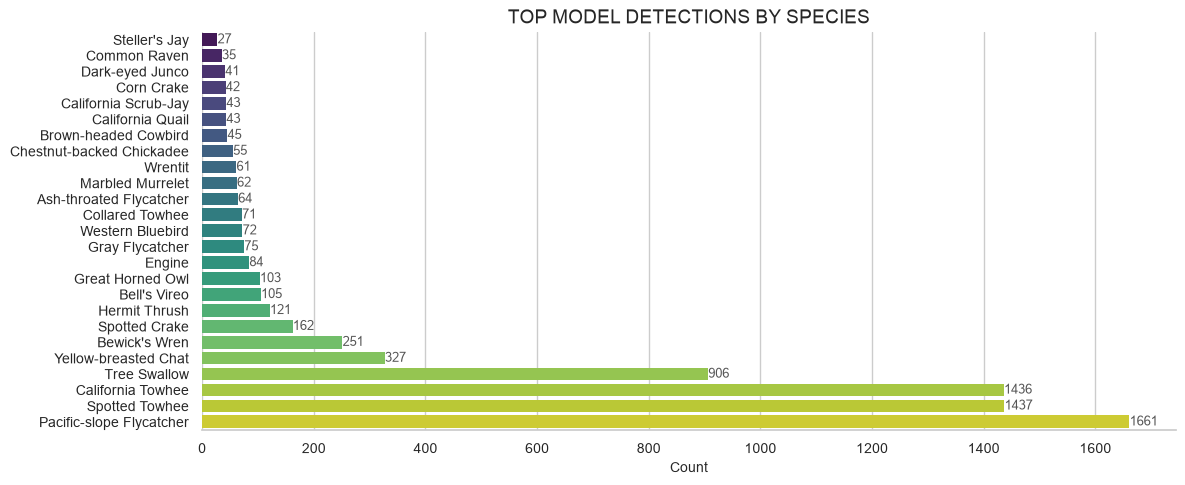

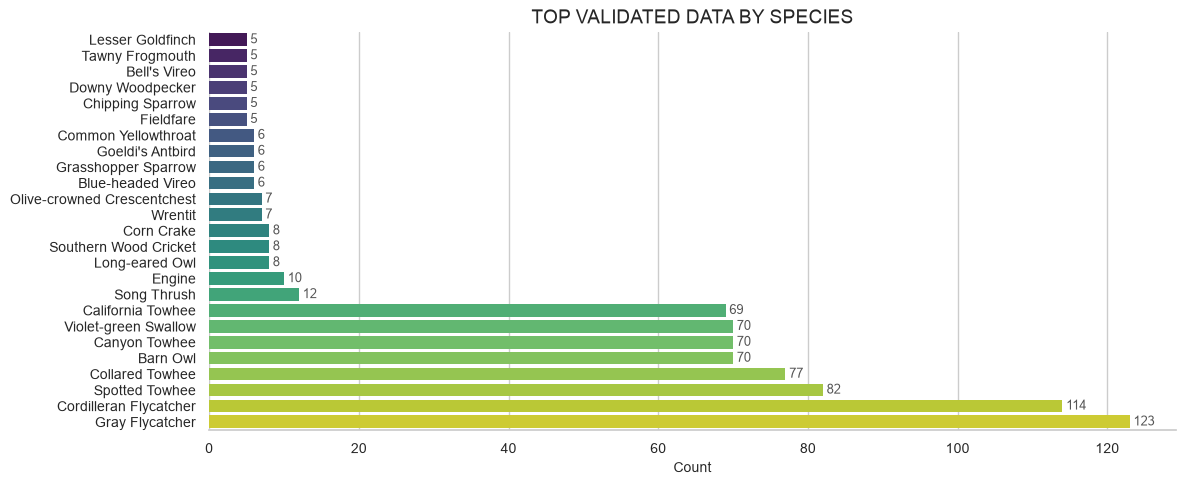

---

In [40]:
%matplotlib inline
analysis = reload(analysis)
display(Markdown('---'))
analysis.species_histogram(df, title='Top Model Detections by Species')
if validated_data is not None and len(validated_data) > 0:
    analysis.species_histogram(validated_data, title='Top Validated Data by Species', column='verified_common_name')
display(Markdown('---'))

### COUNTY LEVEL ANALYSIS

---

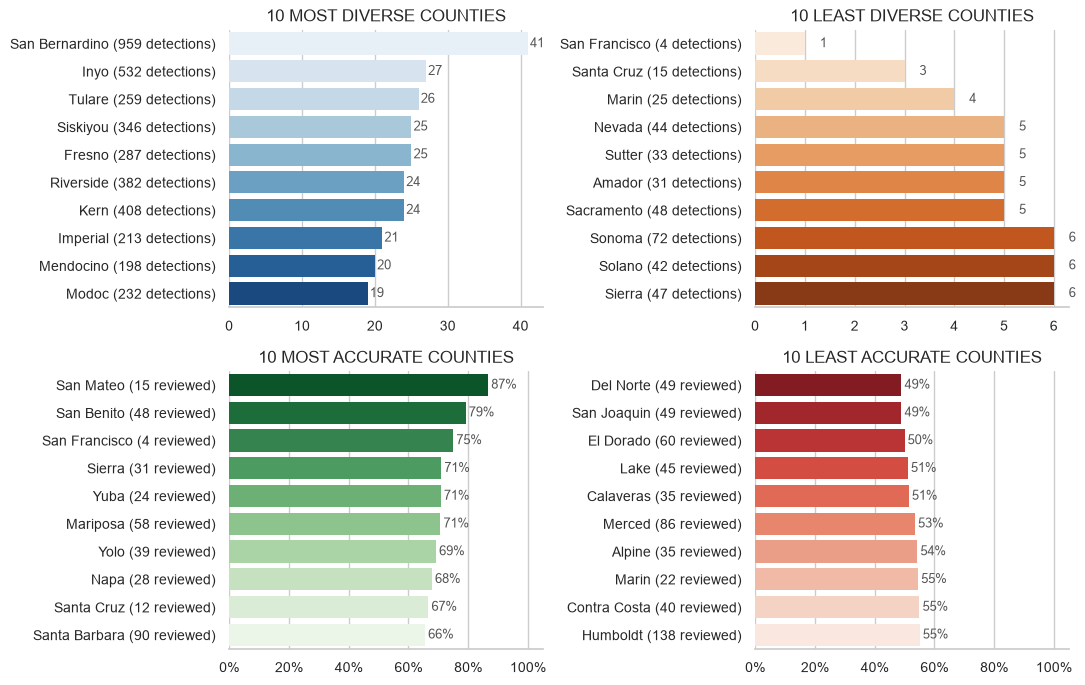

---

In [41]:
%matplotlib inline
analysis = reload(analysis)
display(Markdown('---'))
if validated_data is not None and len(validated_data) > 0:
    analysis.county_distributions(df, validated_data)
else:
    print('Need validated data for county analysis')
display(Markdown('---'))

### COUNTY LEVEL MAPS

In [42]:
MAP_CENTER = (37.5, -119.5)
ZOOM = 6
LAYOUT = {'height': '600px'}

In [43]:
%matplotlib inline
analysis = reload(analysis)

# DOMINANT SPECIES MAP
display(Markdown('---'))
display(Markdown(f'**DOMINANT SPECIES BY COUNTY**'))
m = Map(center=MAP_CENTER, zoom=ZOOM, layout=LAYOUT)
layer, info = analysis.county_species_map(m, df, ca_counties)
display(m, info)
display(Markdown('---'))

# ACCURACY MAP
if validated_data is not None and len(validated_data) > 0:
    display(Markdown(f'**ACCURACY BY COUNTY**'))
    m2 = Map(center=MAP_CENTER, zoom=ZOOM, layout=LAYOUT)
    layer, info = analysis.county_accuracy_map(m2, df, output_df=validated_data, county_geojson=ca_counties)
    display(m2, info)
else:
    print('Need validated data for accuracy map')
display(Markdown('---'))

---

**DOMINANT SPECIES BY COUNTY**

Map(center=[37.5, -119.5], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

Output()

---

**ACCURACY BY COUNTY**

Map(center=[37.5, -119.5], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

Output()

---